# Chapter 36: Attention

Checks [chapter 36](../../book/36-attention.md). The model is exact and small: one attention head on number-valued
tokens (and on 2-dimensional vector values for the hull claim), `softmax` shares over a finite set of tokens, all in NumPy
float64 and seeded. The learning claim uses a **linear model in its weights** (a weight vector, a fixed example matrix), with the
gradient step taken by PyTorch autograd, not by the formula. These are measurements, not proofs: the proofs are in
`Attention.lean` and `AttentionRate.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import torch
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt
from common import use_style, save_figure, report as report_check, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 36
SLACK = 1e-12
COUNTS = {"could fail and passed": 0, "by construction": 0}


def report(label, passed, detail=""):
    """A check that could fail. It stops the notebook if it does, and is counted if it passes."""
    report_check(label, passed, detail)
    COUNTS["could fail and passed"] += 1


def compute_softmax(scores):
    shifted = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return shifted / shifted.sum(axis=-1, keepdims=True)


def attend(score_matrix, values):
    """One head for every query at once: row i of score_matrix scores the tokens for query i."""
    return compute_softmax(score_matrix) @ values


def attend_linearly(scores, values):
    """Attention without the softmax: the sum of score times value."""
    return scores @ values


def report_by_construction(label, passed, detail=""):
    """A formula evaluated, not a model run. It cannot fail, so it is not evidence and is not counted."""
    COUNTS["by construction"] += 1
    print(f"[by construction, cannot fail] {label}" + (f"  ({detail})" if detail else ""))
    assert passed


def shrink_factor(score_bound):
    return 1.0 - np.exp(-2.0 * score_bound)

## Claim 1: the worked example, by hand

Values 2, 4, 9 with shares 0.5, 0.25, 0.25 give 4.25; equal scores give the plain average 5. Then the layer factors:
`1 - exp(-1) = 0.632`, range 7 shrinks to `0.632^10 * 7 = 0.07` after ten layers, and for `score_bound = 3` the factor is `0.9975`
and `0.9975^100 = 0.78`. **Prediction:** the computed numbers match the chapter to the digits printed there. Any mismatch counts against the chapter's arithmetic.
Shares 0.5, 0.25, 0.25 are produced as a softmax of `log` of the shares, so the code path is the head's own.

These four lines evaluate the chapter's formula; they are printed as "by construction, cannot fail" and are not evidence.

In [2]:
values = np.array([2.0, 4.0, 9.0])
scores_for_shares = np.log(np.array([0.5, 0.25, 0.25]))
output = float(compute_softmax(scores_for_shares) @ values)
equal_output = float(compute_softmax(np.zeros(3)) @ values)
report_by_construction("shares 0.5, 0.25, 0.25 give 4.25", abs(output - 4.25) < SLACK, f"output {output:.4f}")
report_by_construction("equal scores give the plain average 5", abs(equal_output - 5.0) < SLACK, f"output {equal_output:.4f}")

factor_half = shrink_factor(0.5)
factor_three = shrink_factor(3.0)
after_one = factor_half * 7
after_ten = factor_half ** 10 * 7
after_hundred = factor_three ** 100
report_by_construction("score_bound 0.5: factor 0.632, 4.4 after one layer, 0.07 after ten",
       round(factor_half, 3) == 0.632 and round(after_one, 1) == 4.4 and round(after_ten, 2) == 0.07,
       f"factor {factor_half:.4f}, after one {after_one:.3f}, after ten {after_ten:.4f}")
report_by_construction("score_bound 3: factor 0.9975 and 0.78 of the spread left after 100 layers",
       round(factor_three, 4) == 0.9975 and round(after_hundred, 2) == 0.78,
       f"factor {factor_three:.5f}, 100 layers {after_hundred:.4f}")

[by construction, cannot fail] shares 0.5, 0.25, 0.25 give 4.25  (output 4.2500)
[by construction, cannot fail] equal scores give the plain average 5  (output 5.0000)
[by construction, cannot fail] score_bound 0.5: factor 0.632, 4.4 after one layer, 0.07 after ten  (factor 0.6321, after one 4.425, after ten 0.0713)
[by construction, cannot fail] score_bound 3: factor 0.9975 and 0.78 of the spread left after 100 layers  (factor 0.99752, 100 layers 0.7802)


## Claim 2: the output lies among the values (`attention_output_lies_among_the_values`)

Draw 20,000 random score vectors (normal, scale 5, so some shares are nearly 0 or 1) for 3 number-valued tokens 2, 4, 9, and for 6 random
2-dimensional vector values test membership of the output in the convex hull with `scipy`'s hull equations. **Prediction:**
no output outside `[2, 9]` and none outside the hull (largest violation at most `1e-9`). **Control:** drop the softmax. With raw positive scores
that do not add to one (`ATTEND_LINEARLY` with scores `exp(score)`), the output must leave `[2, 9]`; the chapter says nothing is held without the shares adding to one.

In [3]:
generator = np.random.default_rng(SEED)
values = np.array([2.0, 4.0, 9.0])
score_draws = generator.normal(0.0, 5.0, size=(20000, 3))
outputs = attend(score_draws, values)
below = float((2.0 - outputs).max())
above = float((outputs - 9.0).max())
report("20,000 random score vectors: every output in [2, 9]", below <= 1e-12 and above <= 1e-12,
       f"lowest output {outputs.min():.6f}, highest {outputs.max():.6f}")

vector_values = generator.normal(size=(6, 2))
hull = ConvexHull(vector_values)
vector_scores = generator.normal(0.0, 3.0, size=(20000, 6))
vector_outputs = compute_softmax(vector_scores) @ vector_values
signed_distance = (vector_outputs @ hull.equations[:, :2].T + hull.equations[:, 2]).max(axis=1)   # positive means outside
report("20,000 outputs on 6 vector values lie in their convex hull", float(signed_distance.max()) <= 1e-9,
       f"largest signed distance beyond a hull edge {float(signed_distance.max()):.1e}")

raw_outputs = attend_linearly(np.exp(score_draws), values)
outside = float(np.mean((raw_outputs < 2.0) | (raw_outputs > 9.0)))
report("control: without the softmax the output leaves [2, 9]", outside > 0.9,
       f"{outside:.3f} of outputs outside, largest {raw_outputs.max():.1f}")

[PASS] 20,000 random score vectors: every output in [2, 9]  (lowest output 2.000000, highest 9.000000)
[PASS] 20,000 outputs on 6 vector values lie in their convex hull  (largest signed distance beyond a hull edge -1.7e-05)
[PASS] control: without the softmax the output leaves [2, 9]  (0.915 of outputs outside, largest 17092535706.2)


## Claim 3: through any number of layers, tokens stay inside their starting range (`attention_alone_never_spreads_the_tokens`)

8 tokens drawn in `[-3, 5]`. Each layer is `APPLY_ATTENTION_LAYER`: every token is a query, and its scores for all tokens
depend on all the current tokens: `score[query, token] = 4 * sin(frequency * tokens[query] * tokens[token] + shift)` with a new random frequency and shift
at every layer, so the scores change with depth and are large. 60 layers, 200 starts. **Prediction:** the lowest token never falls below the
starting minimum and the highest never rises above the starting maximum, at every layer (tolerance `1e-12`). Each layer
is a blend of the current tokens with softmax shares, so this cannot fail short of a bug in the softmax: it is printed
as by construction and not counted.

In [4]:
def apply_attention_layer(tokens, generator, scale=4.0):
    frequency = generator.uniform(0.2, 3.0)
    shift = generator.uniform(0.0, 2 * np.pi)
    scores = scale * np.sin(frequency * np.outer(tokens, tokens) + shift)
    return attend(scores, tokens), scores


generator = np.random.default_rng(SEED + 1)
worst_low, worst_high = 0.0, 0.0
for start in range(200):
    tokens = generator.uniform(-3.0, 5.0, size=8)
    low, high = tokens.min(), tokens.max()
    for layer in range(60):
        tokens, _ = apply_attention_layer(tokens, generator)
        worst_low = max(worst_low, low - tokens.min())
        worst_high = max(worst_high, tokens.max() - high)
report_by_construction("200 starts, 60 layers, changing scores: tokens never leave their starting range (a blend of the tokens cannot leave it)",
       worst_low <= 1e-12 and worst_high <= 1e-12, f"largest escape below {worst_low:.1e}, above {worst_high:.1e}")

[by construction, cannot fail] 200 starts, 60 layers, changing scores: tokens never leave their starting range (a blend of the tokens cannot leave it)  (largest escape below 0.0e+00, above 0.0e+00)


## Claim 4: after `layer_count` layers two tokens differ by at most `(1 - exp(-2 score_bound))^layer_count` times the range (`depth_merges_the_tokens_at_a_geometric_rate`)

8 tokens, uniform in `[0, 7]` (range fixed by pinning the lowest to 0 and the highest to 7), 30 layers, for `score_bound` 0.5, 1 and 3. Two score families, each with every score exactly at or below `score_bound` in size:
random signs `+-score_bound` redrawn each layer, and a **sorting** family `score_bound * sign((query - middle)(token - middle))`, in which each token
prefers tokens on its own side of the middle: the family built to resist merging. The measured spread is the largest difference between any two tokens (`max - min`),
the quantity the theorem bounds for every pair. 300 starts per family. **Prediction:** the measured spread is at most the bound at every layer, in every start.
It could fail if the factor were wrong or the layer map were not an average with floor shares. Layer 0 is left out of the
check: there the spread is 7 and the bound is 7, so the difference is 0 whatever the model does. The tightness is reported
as the worst measured spread over the bound at layers 1, 5, 10, 20 and 30, not asserted beyond `<= 1`; a ratio taken at an early layer, where little has moved, says little about tightness.
**Control:** break the hypothesis `|score| <= score_bound`. Take the same sorting family with score size 50 (near-hard attention) and compare with the bound for `score_bound = 0.5`.
This is a different parameter, not a broken hypothesis of the proved bound: the bound for `score_bound = 0.5` simply does not
apply to scores of size 50. Predicted: the spread exceeds that bound. The spread at layers 0 and 30 is printed with it.

In [5]:
LAYER_COUNT = 30
SCORE_BOUNDS = (0.5, 1.0, 3.0)
TOKEN_COUNT = 8
START_COUNT = 300


def make_scores(tokens, family, score_size, generator):
    if family == "random signs":
        return score_size * generator.choice([-1.0, 1.0], size=(len(tokens), len(tokens)))
    middle = 0.5 * (tokens.min() + tokens.max())
    return score_size * np.sign(np.outer(tokens - middle, tokens - middle) + 1e-12)


def measure_spread(score_size, family, generator, start_count=START_COUNT):
    """Spread (max - min) of the tokens after each of layers 0..LAYER_COUNT, one row per start."""
    spreads = np.zeros((start_count, LAYER_COUNT + 1))
    for start in range(start_count):
        tokens = generator.uniform(0.0, 7.0, size=TOKEN_COUNT)
        tokens[tokens.argmin()] = 0.0
        tokens[tokens.argmax()] = 7.0
        spreads[start, 0] = 7.0
        for layer in range(1, LAYER_COUNT + 1):
            tokens = attend(make_scores(tokens, family, score_size, generator), tokens)
            spreads[start, layer] = tokens.max() - tokens.min()
    return spreads


generator = np.random.default_rng(SEED + 2)
layers = np.arange(LAYER_COUNT + 1)
measured_worst = {}
tightness = {}
for score_bound in SCORE_BOUNDS:
    bound_curve = shrink_factor(score_bound) ** layers * 7.0
    for family in ("random signs", "sorting"):
        spreads = measure_spread(score_bound, family, generator)
        worst_curve = spreads.max(axis=0)
        measured_worst[(score_bound, family)] = worst_curve
        excess = float((spreads[:, 1:] - bound_curve[1:]).max())           # layers 1 to 30; at layer 0 the difference is 0 by definition
        tightness[(score_bound, family)] = {layer: float(worst_curve[layer] / bound_curve[layer]) for layer in (1, 5, 10, 20, 30)}
        report(f"score_bound {score_bound}, {family}: spread <= bound at layers 1 to {LAYER_COUNT}, {START_COUNT} starts",
               excess <= 1e-12, f"largest (spread - bound) {excess:.1e}; at layer {LAYER_COUNT} worst spread {worst_curve[-1]:.3e} against bound {bound_curve[-1]:.3e}; "
               "worst spread / bound at layers 1, 5, 10, 20, 30: " + ", ".join(f"{layer}: {ratio:.3g}" for layer, ratio in tightness[(score_bound, family)].items()))

control_spreads = measure_spread(50.0, "sorting", generator, start_count=50)
control_bound = shrink_factor(0.5) ** layers * 7.0
control_worst = control_spreads.max(axis=0)
report("control: scores of size 50 are a different parameter; their spread exceeds the bound for score_bound 0.5, which does not apply to them",
       float((control_worst - control_bound).max()) > 1.0,
       f"spread {control_worst[0]:.3f} at layer 0 and {control_worst[-1]:.3f} at layer {LAYER_COUNT}, against {control_bound[-1]:.2e} for the score_bound 0.5 bound")

[PASS] score_bound 0.5, random signs: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -7.4e-06; at layer 30 worst spread 1.776e-15 against bound 7.398e-06; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.402, 5: 0.00314, 10: 4.85e-06, 20: 5.5e-12, 30: 2.4e-10)
[PASS] score_bound 0.5, sorting: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -7.4e-06; at layer 30 worst spread 0.000e+00 against bound 7.398e-06; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.54, 5: 0.149, 10: 0.031, 20: 0.00135, 30: 0)
[PASS] score_bound 1.0, random signs: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -8.9e-02; at layer 30 worst spread 2.665e-15 against bound 8.923e-02; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.617, 5: 0.0171, 10: 7.33e-05, 20: 3.86e-09, 30: 2.99e-14)


[PASS] score_bound 1.0, sorting: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -8.8e-02; at layer 30 worst spread 1.558e-03 against bound 8.923e-02; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.693, 5: 0.417, 10: 0.221, 20: 0.0621, 30: 0.0175)
[PASS] score_bound 3.0, random signs: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -6.4e-01; at layer 30 worst spread 2.018e-10 against bound 6.498e+00; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.909, 5: 0.0508, 10: 0.000725, 20: 1.28e-07, 30: 3.11e-11)


[PASS] score_bound 3.0, sorting: spread <= bound at layers 1 to 30, 300 starts  (largest (spread - bound) -1.1e+00; at layer 30 worst spread 4.804e+00 against bound 6.498e+00; worst spread / bound at layers 1, 5, 10, 20, 30: 1: 0.848, 5: 0.8, 10: 0.787, 20: 0.763, 30: 0.739)
[PASS] control: scores of size 50 are a different parameter; their spread exceeds the bound for score_bound 0.5, which does not apply to them  (spread 7.000 at layer 0 and 5.971 at layer 30, against 7.40e-06 for the score_bound 0.5 bound)


## Claim 5: sharp attention merges slowly

The chapter says the bound's factor goes to 1 as `score_bound` grows. Here that is checked as a statement about the *measured* spread, in the sorting family: after 30 layers the worst measured
spread should be larger for `score_bound` 3 than for 1, and larger for 1 than for 0.5. **Prediction:** strictly increasing in `score_bound`. It would fail if sharper attention merged as fast or faster.

In [6]:
final_spreads = [measured_worst[(score_bound, "sorting")][-1] for score_bound in SCORE_BOUNDS]
report("the worst measured spread after 30 layers grows with score_bound",
       final_spreads[0] < final_spreads[1] < final_spreads[2],
       ", ".join(f"score_bound {score_bound}: {spread:.3e}" for score_bound, spread in zip(SCORE_BOUNDS, final_spreads)))

[PASS] the worst measured spread after 30 layers grows with score_bound  (score_bound 0.5: 0.000e+00, score_bound 1.0: 1.558e-03, score_bound 3.0: 4.804e+00)


## Claim 6: one head of linear attention is one gradient step (`one_gradient_step_is_a_linear_attention_head`)

The model is linear in its weights: `prediction(weights) = example_matrix @ weights`, with 5 examples in 4 dimensions and squared loss. PyTorch autograd takes the
gradient at zero weights, and one step with `learning_rate = 0.1`. The query's prediction after the step is compared with `learning_rate * ATTEND_LINEARLY(scores, labels)`,
where `scores = example_matrix @ query_features` is each example's overlap with the query. The chapter's numbers are also run: overlaps 1 and 2, labels 3 and 1, learning rate 0.1 give 0.5.
**Prediction:** equal to within `1e-12` for 100 random queries. **Control:** put the softmax back (`learning_rate * softmax(scores) @ labels`); the chapter says that is not shown, and the two should differ.

In [7]:
generator = np.random.default_rng(SEED + 3)
example_matrix = torch.tensor(generator.normal(size=(5, 4)))
labels = torch.tensor(generator.normal(size=5))
learning_rate = 0.1

weights = torch.zeros(4, requires_grad=True)
loss = 0.5 * ((example_matrix @ weights - labels) ** 2).sum()
loss.backward()
stepped_weights = (weights - learning_rate * weights.grad).detach()

worst_gap = 0.0
softmax_gap = 0.0
for query_index in range(100):
    query_features = torch.tensor(generator.normal(size=4))
    prediction = float(query_features @ stepped_weights)
    overlaps = (example_matrix @ query_features).numpy()
    head_output = learning_rate * float(attend_linearly(overlaps, labels.numpy()))
    softmax_output = learning_rate * float(attend(overlaps, labels.numpy()))
    worst_gap = max(worst_gap, abs(prediction - head_output))
    softmax_gap = max(softmax_gap, abs(prediction - softmax_output))
report("one autograd gradient step from zero equals one head of linear attention, 100 queries", worst_gap < 1e-12, f"largest gap {worst_gap:.1e}")
report("control: with the softmax kept the head is not the gradient step", softmax_gap > 1e-2, f"largest gap {softmax_gap:.3f}")

hand = 0.1 * float(attend_linearly(np.array([1.0, 2.0]), np.array([3.0, 1.0])))
report_by_construction("the chapter's example gives 0.5", abs(hand - 0.5) < SLACK, f"{hand:.4f}")
answer_three = 0.5 * float(attend_linearly(np.array([4.0]), np.array([2.0])))
report_by_construction("check-yourself question 3 gives 4", abs(answer_three - 4.0) < SLACK, f"{answer_three:.4f}")

[PASS] one autograd gradient step from zero equals one head of linear attention, 100 queries  (largest gap 1.1e-16)
[PASS] control: with the softmax kept the head is not the gradient step  (largest gap 0.411)
[by construction, cannot fail] the chapter's example gives 0.5  (0.5000)
[by construction, cannot fail] check-yourself question 3 gives 4  (4.0000)


## Figure 1: a head's output lies among its values

One weight matrix over 6 tokens with values -2, -0.5, 1, 2.5, 4, 7 and random scores. The left panel is the shares (each row adds to one); the right panel puts the token values on a line, with the output of each query row.
Every output is inside the band from the smallest to the largest value (printed as by construction: it is a blend).

[by construction, cannot fail] each row of the figure's shares adds to one and its output is inside the value range  (outputs 2.36, 0.86, 1.71, 1.42, 2.36, 3.14)


wrote book/figures/36-weights-and-outputs.png


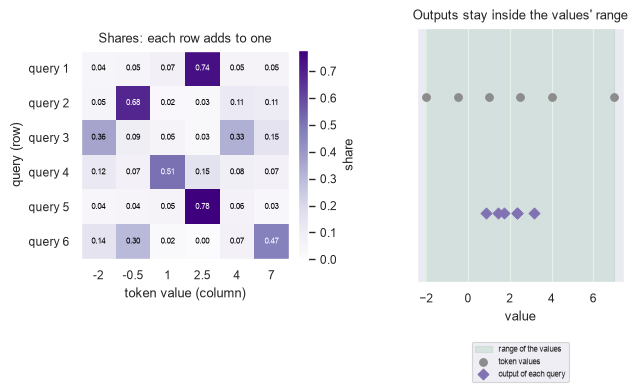

In [8]:
use_style()
generator = np.random.default_rng(SEED + 4)
token_values = np.array([-2.0, -0.5, 1.0, 2.5, 4.0, 7.0])
score_matrix = generator.normal(0.0, 1.5, size=(6, 6))
share_matrix = compute_softmax(score_matrix)
row_outputs = share_matrix @ token_values
report_by_construction("each row of the figure's shares adds to one and its output is inside the value range",
       bool(np.allclose(share_matrix.sum(axis=1), 1.0)) and bool(np.all(row_outputs >= token_values.min())) and bool(np.all(row_outputs <= token_values.max())),
       "outputs " + ", ".join(f"{value:.2f}" for value in row_outputs))

figure, (heat_axis, line_axis) = plt.subplots(1, 2, figsize=(7.0, 3.3), gridspec_kw={"width_ratios": [1.1, 1.0], "wspace": 0.5})
image = heat_axis.imshow(share_matrix, cmap="Purples", vmin=0.0, vmax=share_matrix.max())
for query in range(6):
    for token in range(6):
        heat_axis.text(token, query, f"{share_matrix[query, token]:.2f}", ha="center", va="center", fontsize=6,
                       color="white" if share_matrix[query, token] > 0.5 * share_matrix.max() else "black")
heat_axis.set_xticks(range(6), [f"{value:g}" for value in token_values])
heat_axis.set_yticks(range(6), [f"query {query + 1}" for query in range(6)])
heat_axis.set_xlabel("token value (column)")
heat_axis.set_ylabel("query (row)")
heat_axis.set_title("Shares: each row adds to one")
heat_axis.grid(False)
figure.colorbar(image, ax=heat_axis, fraction=0.046, pad=0.04, label="share")
line_axis.axvspan(token_values.min(), token_values.max(), color=BOUND, alpha=0.15, label="range of the values")
line_axis.scatter(token_values, np.ones(6), color=BEFORE, s=30, label="token values", zorder=3)
line_axis.scatter(row_outputs, np.zeros(6), color=MODEL, s=30, marker="D", label="output of each query", zorder=3)
line_axis.set_ylim(-0.6, 1.6)
line_axis.set_yticks([])
line_axis.set_xlabel("value")
line_axis.set_title("Outputs stay inside the values' range")
line_axis.legend(loc="upper center", fontsize=6, ncol=1, bbox_to_anchor=(0.5, -0.22))
save_figure(figure, "36-weights-and-outputs")
plt.show()

## Figure 2: the spread against the number of layers, with the proved rate

The same measurements as claim 4: the largest spread over 300 starts (`max - min`, purple) for the sorting family, the slower of the two, against the proved bound
`shrink_factor ^ layer_count * range` (green dashed), for each `score_bound`. The left panel also draws the control, scores of size 50, in grey (a different parameter from the proved bound drawn there, which does not apply to it). A measured spread below `1e-12` is rounding error and is not drawn: the line for `score_bound = 0.5` ends where the tokens have merged to machine precision.

wrote book/figures/36-spread-against-layers.png


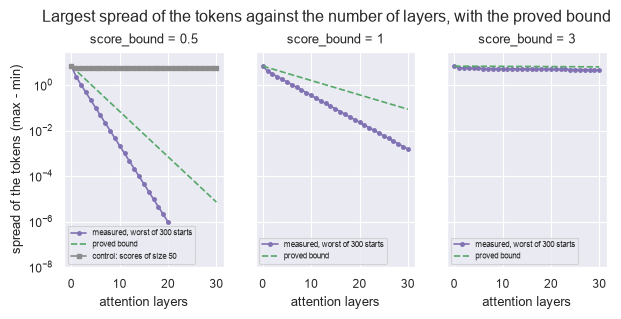

In [9]:
use_style()
DRAW_FLOOR = 1e-12     # a measured spread below 1e-12 is rounding error (the tokens have merged to machine precision); it is not drawn
figure, axes = plt.subplots(1, 3, figsize=(7.0, 2.8), sharey=True)
for axis, score_bound in zip(axes, SCORE_BOUNDS):
    bound_curve = shrink_factor(score_bound) ** layers * 7.0
    axis.semilogy(layers, np.where(measured_worst[(score_bound, "sorting")] > DRAW_FLOOR, measured_worst[(score_bound, "sorting")], np.nan), color=MODEL, marker="o", markersize=2.5, label="measured, worst of 300 starts")
    axis.semilogy(layers, bound_curve, color=BOUND, linestyle="--", label="proved bound")
    if score_bound == 0.5:
        axis.semilogy(layers, control_worst, color=BEFORE, marker="s", markersize=2.5, label="control: scores of size 50")
    axis.set_title(f"score_bound = {score_bound:g}")
    axis.set_xlabel("attention layers")
    axis.legend(fontsize=5.5, loc="lower left")
axes[0].set_ylim(1e-8, 30)
axes[0].set_ylabel("spread of the tokens (max - min)")
figure.suptitle("Largest spread of the tokens against the number of layers, with the proved bound", y=1.03)
save_figure(figure, "36-spread-against-layers")
plt.show()

In [10]:
print(f"checks that could fail and passed: {COUNTS['could fail and passed']}; printed as by construction, not counted: {COUNTS['by construction']}")


checks that could fail and passed: 13; printed as by construction, not counted: 8
